In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from scipy import stats

sns.set_theme(style="whitegrid")
df = pd.read_csv("used-car-price-predictor/data/raw/Car details v3.csv")

REF_YEAR = df["year"].max()            # the data is a snapshot, so age is measured from its newest year
df["car_age"] = REF_YEAR - df["year"]
df["price_lakh"] = df["selling_price"] / 1e5
print(df.shape, "| reference year:", REF_YEAR)

(6918, 16) | reference year: 2020


In [3]:
print("Listings:", len(df))
print("Median price (lakh):", round(df["price_lakh"].median(), 2))
print("Mean price (lakh):", round(df["price_lakh"].mean(), 2))
print("Most common brand:", df["brand"].mode()[0])
print("Most common fuel:", df["fuel"].mode()[0])
print("Median car age (years):", df["car_age"].median())
print("Median km driven:", df["km_driven"].median())

Listings: 6918
Median price (lakh): 4.0
Mean price (lakh): 5.15
Most common brand: Maruti
Most common fuel: Diesel
Median car age (years): 6.0
Median km driven: 70000.0


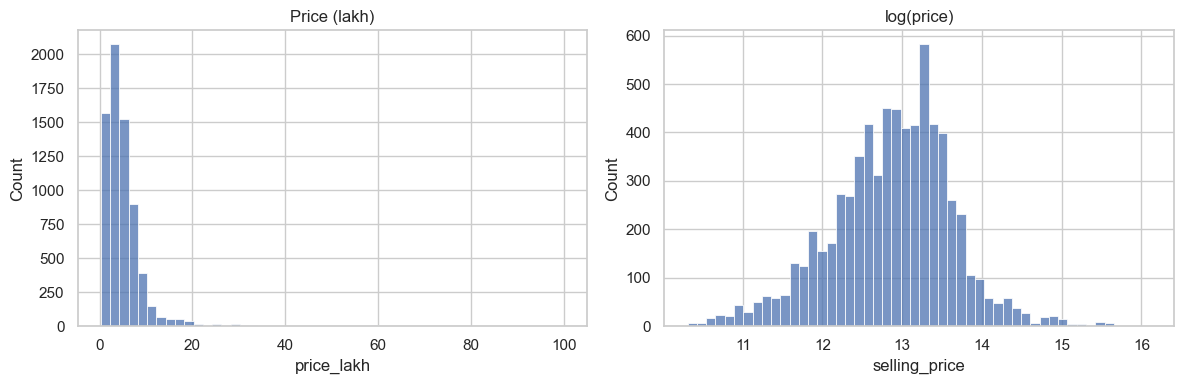

Skewness raw: 5.44 | log: -0.18


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price_lakh"], bins=50, ax=ax[0]); ax[0].set_title("Price (lakh)")
sns.histplot(np.log1p(df["selling_price"]), bins=50, ax=ax[1]); ax[1].set_title("log(price)")
plt.tight_layout()
plt.savefig("used-car-price-predictor/reports/figures/price_distribution.png", dpi=150)
plt.show()
print("Skewness raw:", round(df["selling_price"].skew(), 2),
      "| log:", round(np.log1p(df["selling_price"]).skew(), 2))

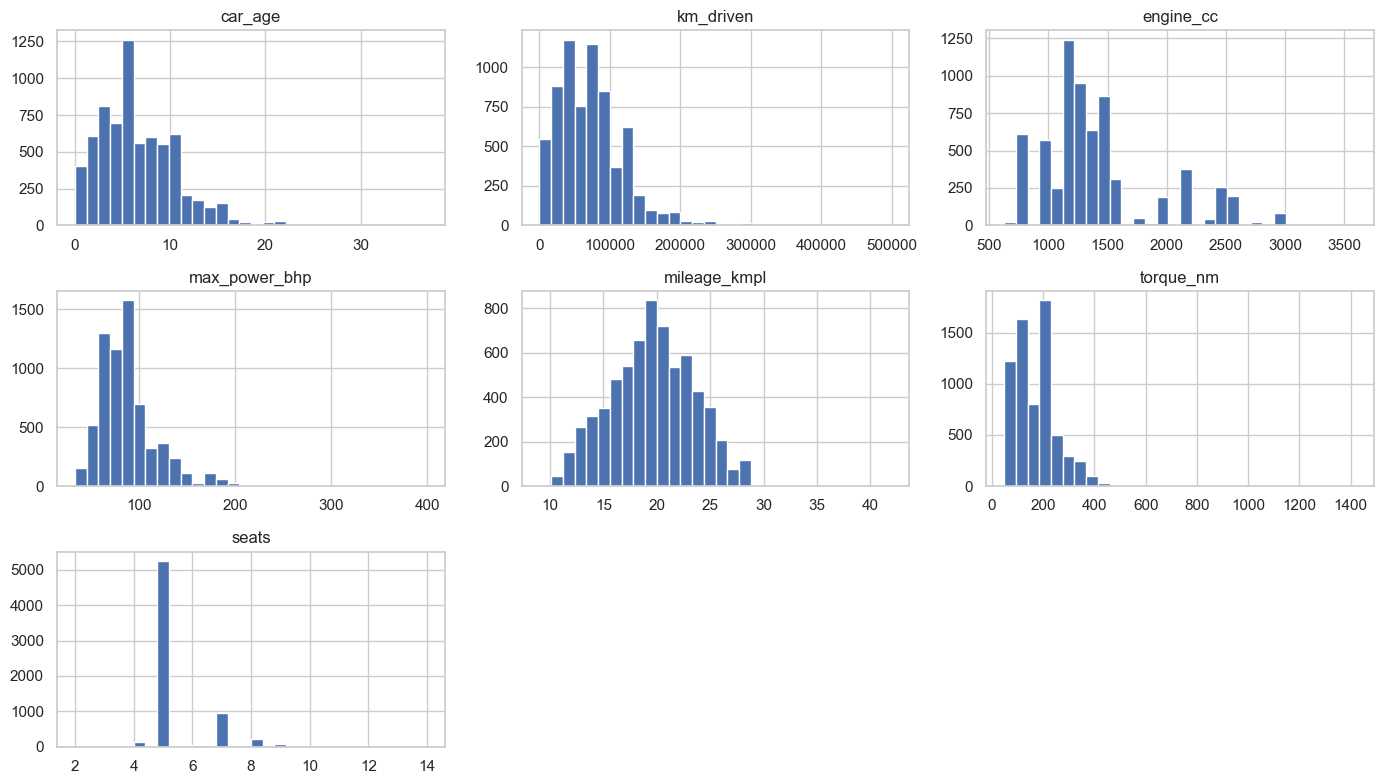

In [6]:
num_cols = ["car_age", "km_driven", "engine_cc", "max_power_bhp", "mileage_kmpl", "torque_nm", "seats"]
df[num_cols].hist(bins=30, figsize=(14, 8))
plt.tight_layout(); plt.show()

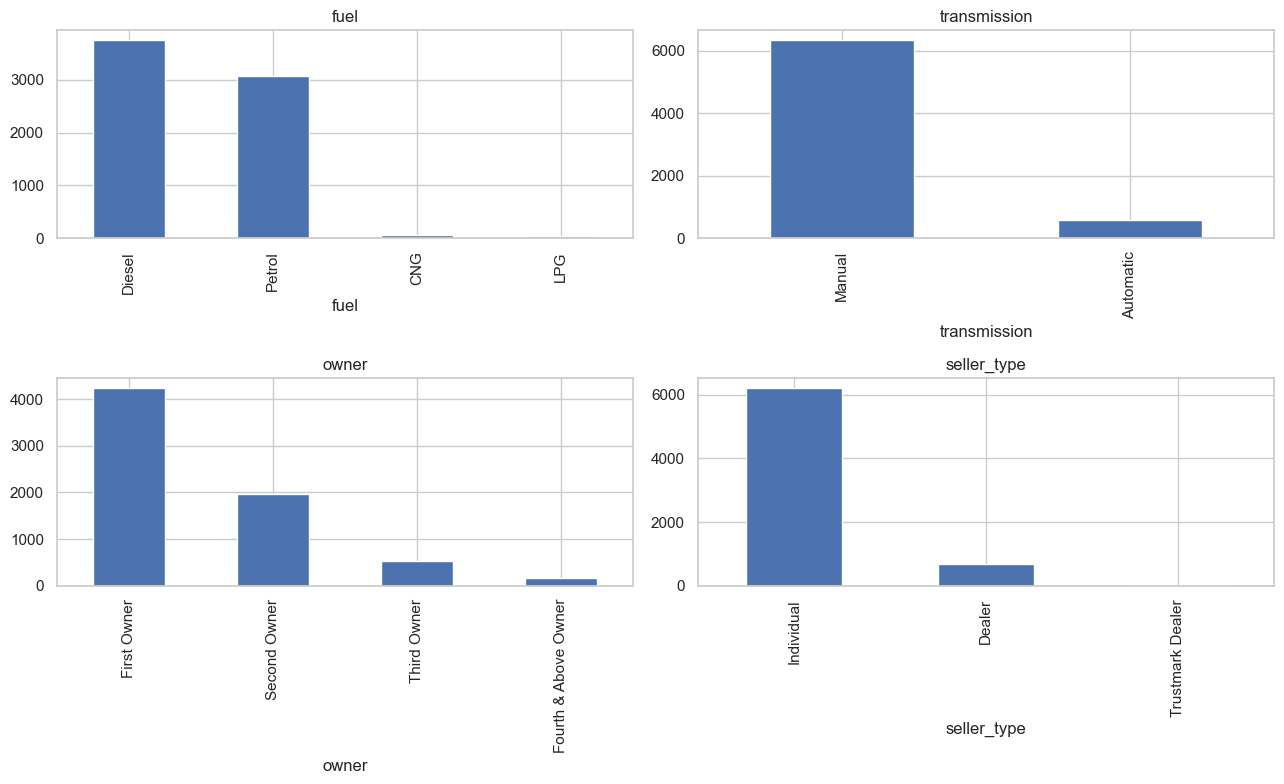

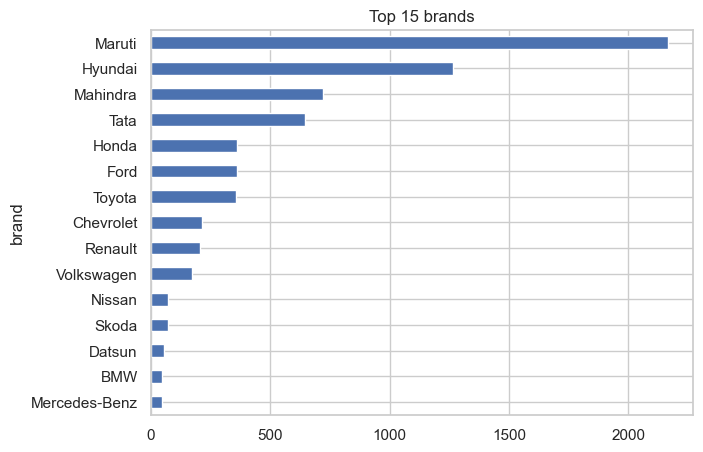

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
for a, col in zip(ax.ravel(), ["fuel", "transmission", "owner", "seller_type"]):
    df[col].value_counts().plot(kind="bar", ax=a, title=col)
plt.tight_layout(); plt.show()

df["brand"].value_counts().head(15).plot(kind="barh", figsize=(7, 5), title="Top 15 brands").invert_yaxis()
plt.show()

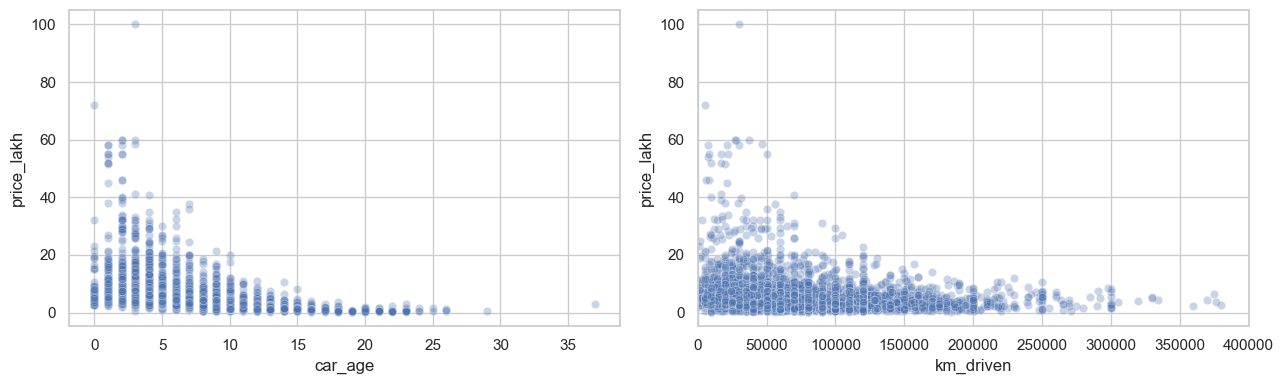

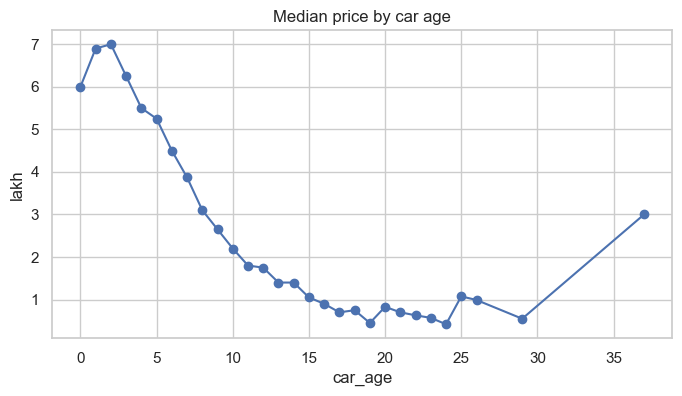

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(data=df, x="car_age", y="price_lakh", alpha=0.3, ax=ax[0])
sns.scatterplot(data=df, x="km_driven", y="price_lakh", alpha=0.3, ax=ax[1])
ax[1].set_xlim(0, 400000)
plt.tight_layout(); plt.show()

df.groupby("car_age")["price_lakh"].median().plot(marker="o", figsize=(8, 4), title="Median price by car age")
plt.ylabel("lakh")
plt.savefig("used-car-price-predictor/reports/figures/depreciation.png", dpi=150)
plt.show()

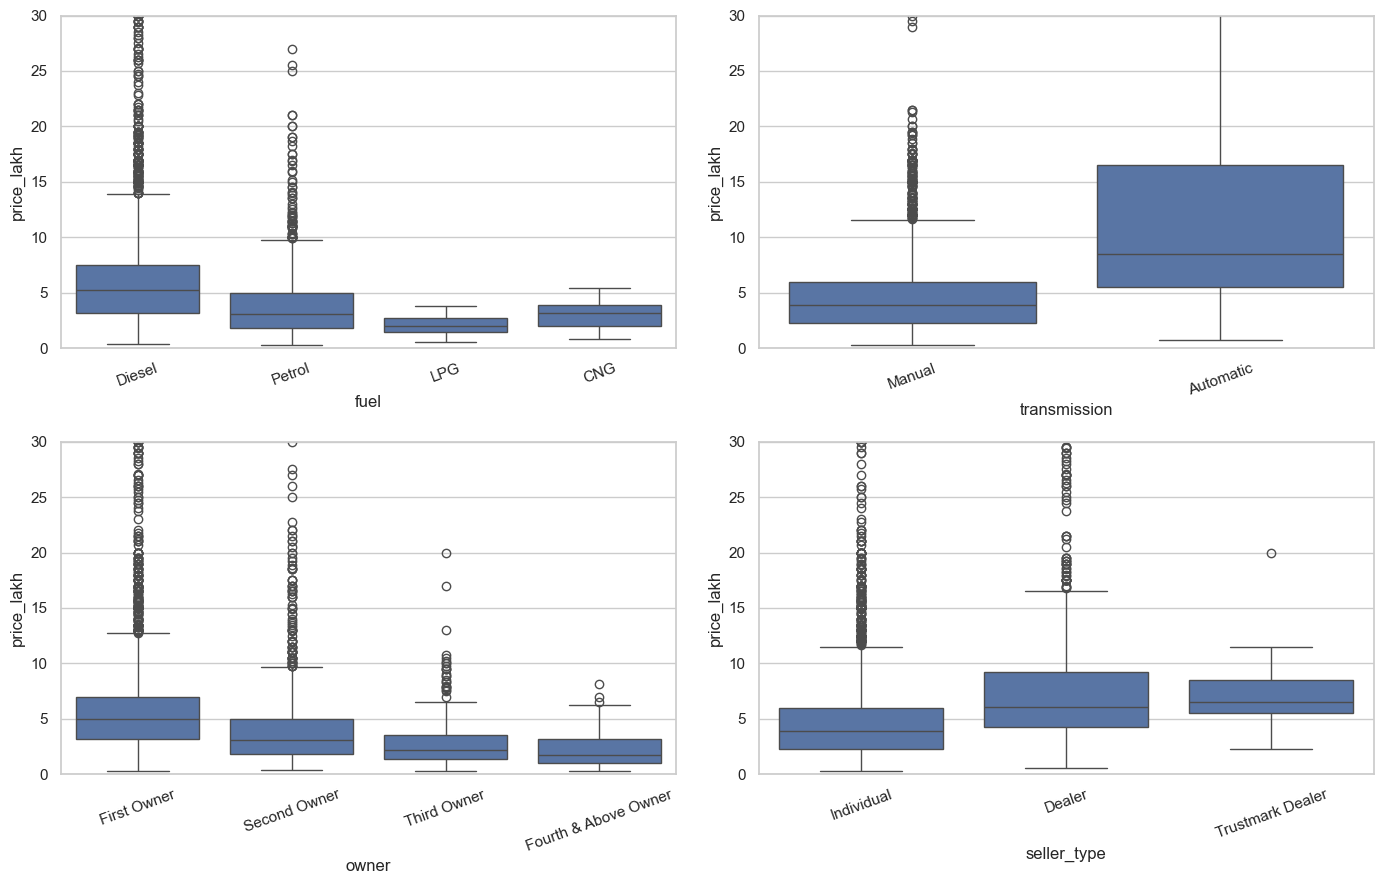

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
for a, col in zip(ax.ravel(), ["fuel", "transmission", "owner", "seller_type"]):
    sns.boxplot(data=df, x=col, y="price_lakh", ax=a)
    a.set_ylim(0, 30)                      # display limit only, no data removed
    a.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

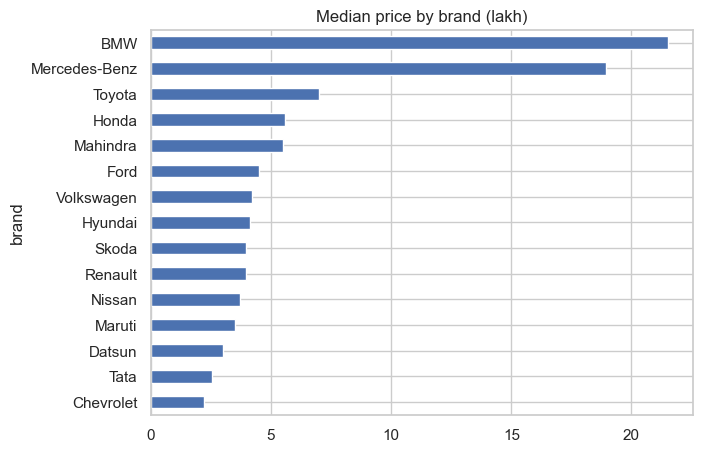

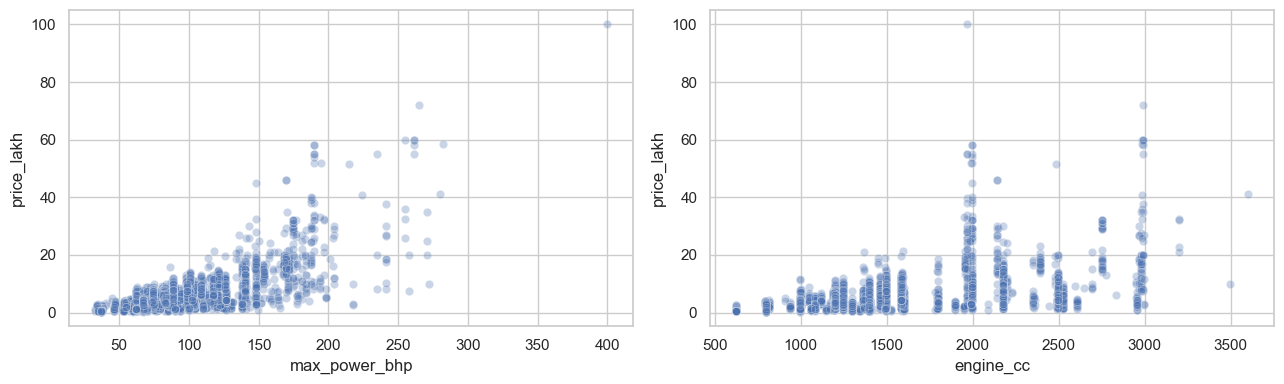

In [11]:
top = df["brand"].value_counts().head(15).index
(df[df["brand"].isin(top)].groupby("brand")["price_lakh"].median().sort_values()
   .plot(kind="barh", figsize=(7, 5), title="Median price by brand (lakh)"))
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(data=df, x="max_power_bhp", y="price_lakh", alpha=0.3, ax=ax[0])
sns.scatterplot(data=df, x="engine_cc", y="price_lakh", alpha=0.3, ax=ax[1])
plt.tight_layout(); plt.show()

In [12]:
df.groupby("fuel").agg(count=("price_lakh", "size"),
                       median_price=("price_lakh", "median"),
                       avg_mileage=("mileage_kmpl", "mean")).round(2)

,count,median_price,avg_mileage
fuel,,,
CNG,56,3.20,23.99
Diesel,3753,5.20,19.77
LPG,38,1.96,18.58
Petrol,3071,3.10,19.13


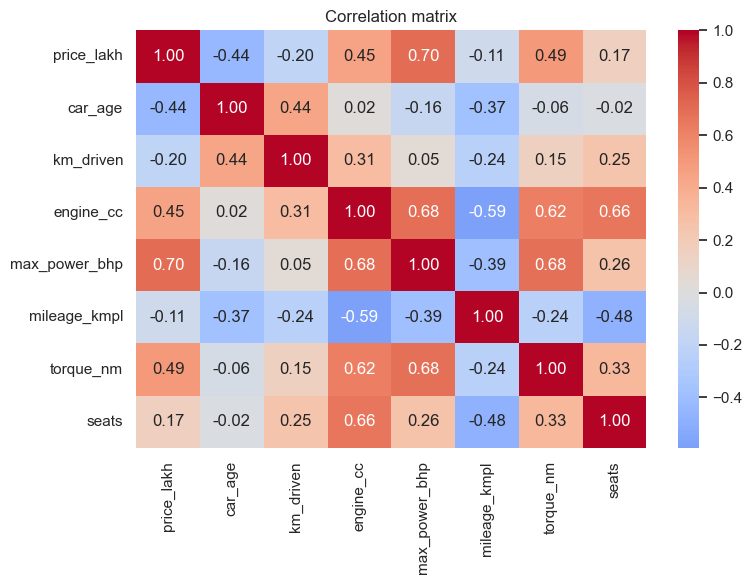

In [14]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[["price_lakh"] + num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.tight_layout()
plt.savefig("used-car-price-predictor/reports/figures/correlation.png", dpi=150)
plt.show()

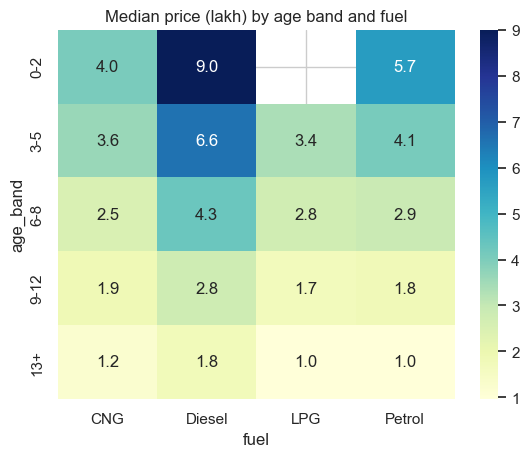

In [15]:
df["age_band"] = pd.cut(df["car_age"], [-1, 2, 5, 8, 12, 50], labels=["0-2", "3-5", "6-8", "9-12", "13+"])
pivot = df.pivot_table(index="age_band", columns="fuel", values="price_lakh", aggfunc="median", observed=True)
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="YlGnBu")
plt.title("Median price (lakh) by age band and fuel"); plt.show()

fig = px.scatter(df, x="car_age", y="price_lakh", color="fuel", hover_data=["name"],
                 opacity=0.6, title="Price vs age by fuel")
fig.update_yaxes(range=[0, 40]); fig.show()

In [ ]:
#Testes
# Spearman: works for non-linear but consistently rising or falling relationships
for c in ["car_age", "km_driven", "max_power_bhp", "engine_cc"]:
    r, p = stats.spearmanr(df[c], df["price_lakh"], nan_policy="omit")
    print(f"{c:15s} Spearman r = {r:.2f}  (p = {p:.3g})")

# Automatic vs manual (Mann-Whitney U, because price is skewed)
a = df.loc[df["transmission"] == "Automatic", "price_lakh"]
m = df.loc[df["transmission"] == "Manual", "price_lakh"]
print("\nMedian Automatic:", round(a.median(), 2), "| Manual:", round(m.median(), 2),
      "| p =", stats.mannwhitneyu(a, m).pvalue)

# Do fuel types differ in price? (Kruskal-Wallis)
groups = [g["price_lakh"].values for _, g in df.groupby("fuel")]
print("Fuel types Kruskal-Wallis p =", stats.kruskal(*groups).pvalue)

car_age         Spearman r = -0.70  (p = 0)
km_driven       Spearman r = -0.29  (p = 2.61e-132)
max_power_bhp   Spearman r = 0.63  (p = 0)
engine_cc       Spearman r = 0.48  (p = 0)

Median Automatic: 8.45 | Manual: 3.85 | p = 2.5075855989070573e-138
Fuel types Kruskal-Wallis p = 5.734386486392775e-202
